# Double descent — book graphics 2: regularization sweep

Still version of the `p20_2` manim scene in `p20.py`: a degree-3 Legendre **ridge** fit to the same seed-428 data, swept over the regularization strength λ, with the curves colored by λ along a colormap.

The curves are recomputed here with the same `fit_legendre_ridge` recipe that produced `regularization_fits_oct_15_1.npy` (`Final Video Polynomial Examples.ipynb`, cell 15: degree 3, λ = 0, 0.01, …, 0.30), so they match the video.

Exports (all with identical axis scale, same as graphics 1):

- `reg_sweep.svg` — all curves over the data and the underlying function, clipped to `YLIM`
- `reg_sweep_unclipped.svg` — same, y-range widened to contain every curve at the same inches-per-unit
- `reg_sweep_colorbar.svg` — standalone λ colorbar to place in Illustrator


## 1. Config

In [7]:
import os
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MultipleLocator

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'

AXIS_COLOR   = CHILL_BROWN
CURVE_COLOR  = CHILL_BROWN   # underlying function f(x)
TRAIN_COLOR  = LT_BLUE
TEST_COLOR   = ORANGE

# ── Data (matches p8_15.py / p20.py) ───────────────────────────────────────
RANDOM_SEED = 428
N_POINTS    = 10
NOISE_LEVEL = 0.2
TRAIN_FRAC  = 0.5
X_MIN, X_MAX = -2.0, 2.0
def f(x): return 0.5 * x**2

# ── Regularization sweep (matches the npy recipe) ──────────────────────────
DEGREE      = 3
LAMBDAS     = np.arange(0, 0.31, 0.01)   # 31 values; e.g. np.linspace(0, 0.3, 7) for a sparser set
def make_book_viridis(end_color='#fcc947', blend_start=0.6, n=256):
    """viridis, but the top end bends smoothly into `end_color` instead of viridis's yellow.
    Identical to viridis below `blend_start`; smoothstep-blended toward end_color above it."""
    base = mpl.colormaps['viridis']
    t = np.linspace(0, 1, n)
    cols = base(t)[:, :3]
    delta = np.array(mpl.colors.to_rgb(end_color)) - cols[-1]
    w = np.clip((t - blend_start) / (1 - blend_start), 0, 1)
    w = w * w * (3 - 2 * w)
    return mpl.colors.ListedColormap(np.clip(cols + w[:, None] * delta[None, :], 0, 1), name='book_viridis')

CMAP        = make_book_viridis('#fcc947', blend_start=0.6)   # or a name like 'viridis' / 'viridis_r'
CMAP_RANGE  = (0.0, 1.0)                 # fraction of the colormap to use, e.g. (0, 0.85) to avoid the pale yellow end
FIT_LINEWIDTH = 1.5
FIT_ALPHA     = 1.0
HIGHLIGHT_LAMBDAS = []                   # e.g. [0.0, 0.3]: these get drawn on top at HIGHLIGHT_LINEWIDTH
HIGHLIGHT_LINEWIDTH = 2.5

# ── Figure styling (same as graphics 1) ────────────────────────────────────
AX_WIDTH_IN     = 4.0          # axes box width in inches (x-range XLIM maps onto this)
AX_HEIGHT_IN    = 3.4          # axes box height in inches for the clipped y-range YLIM
MARGIN_IN       = 0.6
LINEWIDTH       = 2.0          # underlying curve
AXIS_LINEWIDTH  = 1.0
DOT_SIZE        = 100
FONTSIZE        = 10
XLIM            = (X_MIN, X_MAX)
YLIM            = (-0.5, 2.0)  # clipped y-range
UNCLIP_PAD      = 0.25
X_TICK_STEP     = 1.0
Y_TICK_STEP     = 1.0
SPINES          = 'lb'         # 'lb' = left+bottom only, 'box' = all four
SHOW_TICKS      = True
CURVE_ALPHA     = 0.5          # opacity of the underlying f(x) curve
CURVE_LINESTYLE = '-'
SHOW_POINTS     = True
TRANSPARENT     = True

# ── Colorbar export ────────────────────────────────────────────────────────
CBAR_SIZE_IN    = (0.18, AX_HEIGHT_IN)   # (width, height) of the colorbar bar
CBAR_TICKS      = [0.0, 0.1, 0.2, 0.3]
CBAR_LABEL      = r'$\lambda$'

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = False
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Illustrator

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/regularization_sweep')
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Fit helpers

In [8]:
def legendre_features(x, degree, x_min=X_MIN, x_max=X_MAX):
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    feature_degrees = np.arange(degree + 1)[:, None]
    return scipy.special.eval_legendre(feature_degrees, x_scaled).T

def fit_legendre_ridge(x_train, y_train, degree, lambda_reg=0.0):
    """Ridge regression on Legendre features: beta = (X^T X + lambda I)^{-1} X^T y  (lambda=0 -> plain least squares)."""
    X = legendre_features(x_train, degree)
    I = np.eye(X.shape[1])
    return np.linalg.solve(X.T @ X + lambda_reg * I, X.T @ y_train)

def eval_legendre_poly(beta, x, degree):
    return legendre_features(x, degree) @ beta

def get_noisy_data(n_points=N_POINTS, noise_level=NOISE_LEVEL, random_seed=RANDOM_SEED):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y


## 3. Data + sweep

In [9]:
x, y = get_noisy_data()
n_train = int(np.floor(N_POINTS * TRAIN_FRAC))
x_train, y_train = x[:n_train], y[:n_train]
x_test,  y_test  = x[n_train:], y[n_train:]

all_x = np.linspace(X_MIN, X_MAX, 256)
all_y = f(all_x)

sweep = []
for lam in LAMBDAS:
    beta = fit_legendre_ridge(x_train, y_train, DEGREE, lam)
    sweep.append(dict(
        lam       = lam,
        beta      = beta,
        curve     = eval_legendre_poly(beta, all_x, DEGREE),
        train_mse = np.mean((y_train - eval_legendre_poly(beta, x_train, DEGREE))**2),
        test_mse  = np.mean((y_test  - eval_legendre_poly(beta, x_test,  DEGREE))**2),
    ))
all_fits = np.array([s['curve'] for s in sweep])

print(f"{'lambda':>7} {'train MSE':>10} {'test MSE':>10} {'curve y-range':>22}")
for s in sweep:
    c = s['curve']
    print(f"{s['lam']:>7.2f} {s['train_mse']:>10.4f} {s['test_mse']:>10.4f} {c.min():>10.2f} .. {c.max():<8.2f}")


 lambda  train MSE   test MSE          curve y-range
   0.00     0.0008     0.7270      -0.67 .. 4.02    
   0.01     0.0020     0.4851      -0.53 .. 3.54    
   0.02     0.0043     0.3488      -0.43 .. 3.19    
   0.03     0.0070     0.2666      -0.35 .. 2.93    
   0.04     0.0096     0.2146      -0.29 .. 2.73    
   0.05     0.0120     0.1808      -0.25 .. 2.57    
   0.06     0.0144     0.1585      -0.21 .. 2.43    
   0.07     0.0165     0.1436      -0.18 .. 2.32    
   0.08     0.0186     0.1339      -0.15 .. 2.22    
   0.09     0.0205     0.1278      -0.13 .. 2.13    
   0.10     0.0224     0.1242      -0.11 .. 2.06    
   0.11     0.0241     0.1225      -0.09 .. 1.99    
   0.12     0.0258     0.1221      -0.07 .. 1.93    
   0.13     0.0274     0.1229      -0.06 .. 1.88    
   0.14     0.0290     0.1244      -0.04 .. 1.83    
   0.15     0.0305     0.1265      -0.03 .. 1.79    
   0.16     0.0319     0.1292      -0.02 .. 1.75    
   0.17     0.0334     0.1322      -0.01 .. 1.

## 4. Renderers

In [10]:
X_IN_PER_UNIT = AX_WIDTH_IN  / (XLIM[1] - XLIM[0])
Y_IN_PER_UNIT = AX_HEIGHT_IN / (YLIM[1] - YLIM[0])

cmap = mpl.colormaps[CMAP] if isinstance(CMAP, str) else CMAP
norm = mpl.colors.Normalize(vmin=LAMBDAS.min(), vmax=LAMBDAS.max())
def lam_color(lam):
    """Map lambda -> color, using only the CMAP_RANGE slice of the colormap."""
    t = CMAP_RANGE[0] + (CMAP_RANGE[1] - CMAP_RANGE[0]) * norm(lam)
    return cmap(t)

def exact_axes(width_in, height_in, margin=MARGIN_IN):
    fig = plt.figure(figsize=(width_in + 2 * margin, height_in + 2 * margin))
    ax = fig.add_axes([margin / fig.get_figwidth(), margin / fig.get_figheight(),
                       width_in / fig.get_figwidth(), height_in / fig.get_figheight()])
    return fig, ax

def style_ax(ax, color=AXIS_COLOR):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    ax.xaxis.label.set_color(color)
    ax.yaxis.label.set_color(color)
    if not SHOW_TICKS:
        ax.set_xticks([]); ax.set_yticks([])

def sweep_ylim(clip=True):
    if clip:
        return YLIM
    return (min(YLIM[0], all_fits.min() - UNCLIP_PAD), max(YLIM[1], all_fits.max() + UNCLIP_PAD))

def draw_sweep(ax, clip=True):
    ylim = sweep_ylim(clip)
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, ls=CURVE_LINESTYLE,
            alpha=CURVE_ALPHA, zorder=1, solid_capstyle='round')
    for s in sweep:   # drawn in lambda order, so later (higher-lambda) curves sit on top
        ax.plot(all_x, s['curve'], color=lam_color(s['lam']), lw=FIT_LINEWIDTH,
                alpha=FIT_ALPHA, zorder=2, solid_capstyle='round')
    for lam in HIGHLIGHT_LAMBDAS:
        s = min(sweep, key=lambda s: abs(s['lam'] - lam))
        ax.plot(all_x, s['curve'], color=lam_color(s['lam']), lw=HIGHLIGHT_LINEWIDTH,
                zorder=4, solid_capstyle='round')
    if SHOW_POINTS:
        ax.scatter(x_train, y_train, s=DOT_SIZE, color=TRAIN_COLOR, zorder=3, linewidths=0)
        ax.scatter(x_test,  y_test,  s=DOT_SIZE, color=TEST_COLOR,  zorder=3, linewidths=0)
    ax.set_xlim(*XLIM); ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    style_ax(ax)

def sweep_figure(clip=True):
    ylim = sweep_ylim(clip)
    fig, ax = exact_axes(AX_WIDTH_IN, (ylim[1] - ylim[0]) * Y_IN_PER_UNIT)
    draw_sweep(ax, clip)
    return fig, ax

def colorbar_figure():
    """Standalone vertical colorbar for lambda, using the same CMAP_RANGE slice."""
    w, h = CBAR_SIZE_IN
    fig, ax = exact_axes(w, h)
    sliced = mpl.colors.ListedColormap(cmap(np.linspace(CMAP_RANGE[0], CMAP_RANGE[1], 256)))
    cb = mpl.colorbar.ColorbarBase(ax, cmap=sliced, norm=norm, orientation='vertical', ticks=CBAR_TICKS)
    cb.outline.set_edgecolor(AXIS_COLOR); cb.outline.set_linewidth(AXIS_LINEWIDTH)
    cb.ax.tick_params(colors=AXIS_COLOR, labelsize=FONTSIZE, width=AXIS_LINEWIDTH)
    cb.set_label(CBAR_LABEL, color=AXIS_COLOR, fontsize=FONTSIZE + 2, rotation=0, labelpad=8)
    return fig, ax


## 5. Preview

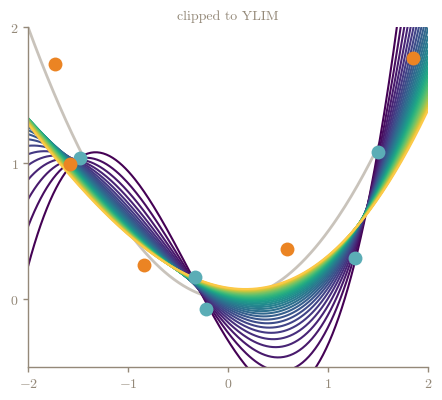

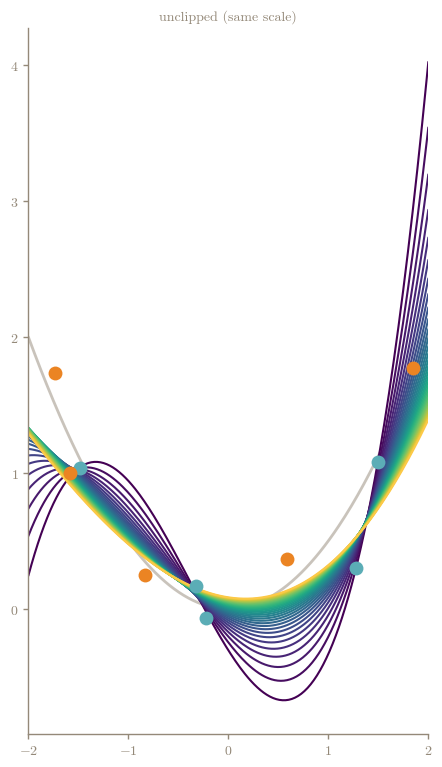

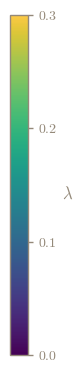

In [11]:
fig, ax = sweep_figure(clip=True);  ax.set_title('clipped to YLIM', color=AXIS_COLOR, fontsize=FONTSIZE); plt.show()
fig, ax = sweep_figure(clip=False); ax.set_title('unclipped (same scale)', color=AXIS_COLOR, fontsize=FONTSIZE); plt.show()
fig, ax = colorbar_figure(); plt.show()


## 6. Export

In [12]:
def save(fig, stem):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

if SAVE:
    fig, _ = sweep_figure(clip=True);  save(fig, 'reg_sweep')
    fig, _ = sweep_figure(clip=False); save(fig, 'reg_sweep_unclipped')
    fig, _ = colorbar_figure();        save(fig, 'reg_sweep_colorbar')
    print('saved to', OUT_DIR.resolve())
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/regularization_sweep
   reg_sweep.svg
   reg_sweep_colorbar.svg
   reg_sweep_unclipped.svg


The thing you're minimizing is the ordinary training loss plus a penalty on the size of the coefficients, and λ is the dial on that penalty:

$$
\mathcal{L}(\boldsymbol\beta) \;=\; \sum_{i=1}^{n}\bigl(y_i - \hat y_i\bigr)^2 \;+\; \lambda \sum_{k=0}^{3} \beta_k^2
$$

with $\hat y_i = \beta_0 + \beta_1 P_1(x_i) + \beta_2 P_2(x_i) + \beta_3 P_3(x_i)$ for the Legendre basis (or just write it as a cubic if the basis isn't something the chapter has introduced). Reads cleanly: λ = 0 is the unregularized fit you already showed, and bigger λ pulls the β's toward zero, which is exactly the fan flattening toward the gold curves.

If you want the closed form that the code actually computes, it's one line:

$$
\hat{\boldsymbol\beta} \;=\; \bigl(X^{\top}X + \lambda I\bigr)^{-1} X^{\top}\mathbf{y}
$$

and you can point at the $+\lambda I$ as the only difference from plain least squares.

One thing to be careful about: your code's objective is the **sum** of squared errors, not the mean. If you write the first term as MSE (divided by n) in the book, the λ values on your colorbar would be off by a factor of n = 5 — the λ = 0.3 curve corresponds to λ = 0.06 in the MSE form. So either write it as a sum, as above, or label the colorbar as $5\lambda$... the sum form is simpler.